# Introducing stellar activity with HARPS-N

Understanding and mitigating stellar variability, which is thought to be the dominant barrier to detecting Earth-like planets, requires an understanding of stellar activity which in turn requires a large number of high-quality stellar spectra.

Here we use the curated [HARPS-N solar RVs](https://dace.unige.ch/openData/?record=10.82180/dace-h4s8lp7c$0), which contain a total of 109,466 good-quality observations (out of 173,793 in total) taken between 14 July 2015 to 5 May 2025. We then add the solar RVs to to the 'clean' planetary RV signals which we derived in the previous notebook to see what impact stellar activity has on measured RVs.

We download the time series under '2015-2025.tar.gz', with the RVs stored in a CSV file. 

In the README.pdf of the HARPS-N solar data, a description of the headers in the file are given. We extract 'RV' which is the RV of the Sun in the heliocentric rest frame with corrections from a barycentric frame of reference (removing reflex motion of Sun), leaving only stellar activity and instrunental effects.

Note 'RV' units are 'km/s' so need to be converted to 'm/s'.

### Importing data & libraries

In [3]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import scipy.stats as stats
from scipy.signal import lombscargle


clean_rv_data = np.load('solar_system_rvs.npz')
time, radial_velocity, planets = clean_rv_data['time'], clean_rv_data['radial_velocity'], list(clean_rv_data['planets'])

df = pd.read_csv('harpn_sun_release_timeseries_2015-2025.csv')
df_rvs = df[['night','data_quality','obs_quality','rv']].copy() # extract the night data taken, data quality and raw rv.
df_rvs['rv'] = df_rvs['rv'] * 1000 # convert raw rv from km/s to m/s

### Daily binning of raw data.

Since the data are taken every 5 minutes (exposure time) and our modelled RV values are at daily intervals, we take the average RV of all values in one night. 

Note, one night here is given as the day in which the data were taken, from 9am to 9am the next day.

In [4]:
quality_df_rvs = df_rvs[df_rvs['data_quality']==1]
quality_df_rvs_rms = np.sqrt(np.nanmean(quality_df_rvs['rv']**2))

daily_binned_solar_rvs = quality_df_rvs.groupby('night')['rv'].mean()
dates = pd.date_range(start='2015-07-14', end='2025-05-05', freq='D')

# Convert the index of daily_binned_solar_rvs to datetime objects
daily_binned_solar_rvs.index = pd.to_datetime(daily_binned_solar_rvs.index)

# Reindex using the complete date range. We fill missing days with NaN instead of 0.0 to prevent rolling window bias.
daily_binned_solar_rvs = daily_binned_solar_rvs.reindex(dates, fill_value=np.nan)

# Calculate RMS ignoring NaN values
daily_binned_solar_rvs_rms = np.sqrt(np.nanmean(daily_binned_solar_rvs**2))

### Mitigating rotation with 30-day smoothing of daily binned data.

We also take a 30-day moving average so as to mitigate stellar acitivity from the rotation of the Sun (which is approx 30 days).

***Q: Is the exoplanet's host star rotational period typically known, and is this smoothing then applied?***

***Q: How is the exoplanet's host star rotational period typically known?***

In [5]:
# Calculate 30-day rolling mean. Using min_periods=1 allows calculation as long as there is at least 1 real observation in the window
smoothed_solar_rvs = daily_binned_solar_rvs.rolling('30D', min_periods=1, center=True).mean()
smoothed_solar_rvs_rms = np.sqrt(np.nanmean(smoothed_solar_rvs**2))

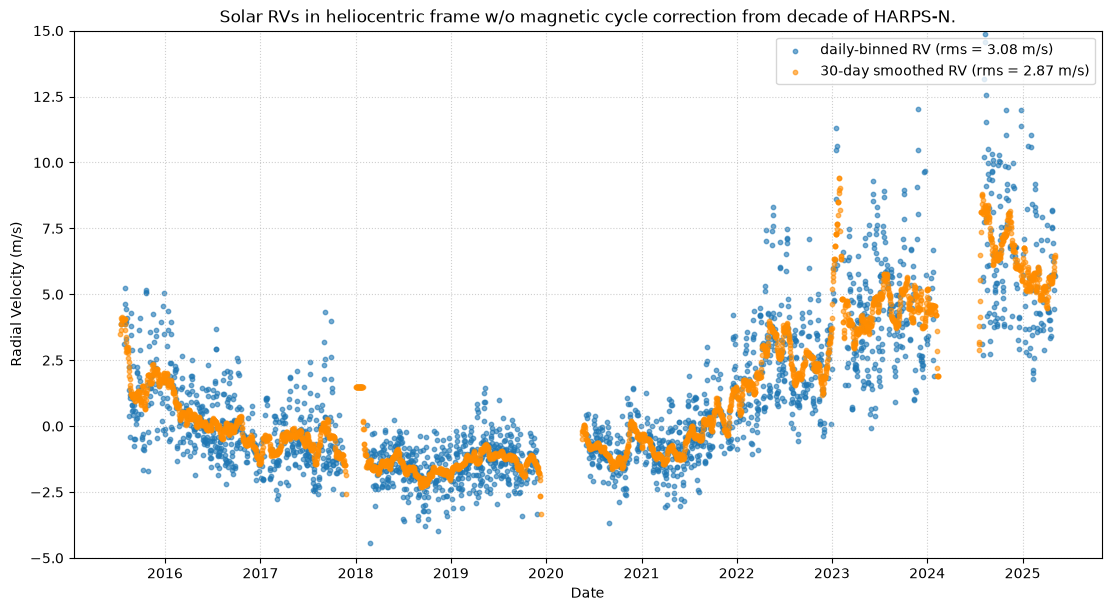

In [6]:
fig, ax = plt.subplots(figsize=(11, 6), layout='constrained')

ax.scatter(daily_binned_solar_rvs.index, daily_binned_solar_rvs, alpha=0.6,
           label=f'daily-binned RV (rms = {daily_binned_solar_rvs_rms:.2f} m/s)', s=10, zorder=1)

ax.scatter(smoothed_solar_rvs.index, smoothed_solar_rvs, color='darkorange', alpha=0.6, s=10,
           label=f'30-day smoothed RV (rms = {smoothed_solar_rvs_rms:.2f} m/s)', zorder=2)

ax.set_title('Solar RVs in heliocentric frame w/o magnetic cycle correction from decade of HARPS-N.')
ax.set_xlabel('Date')
ax.set_ylabel('Radial Velocity (m/s)')
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc='upper right')
ax.set_ylim([-5, 15])

plt.show()

The solar RVs are not stable on the long-term due to the magnetic cycle. Those RVs should be strongly correlated on long-timescales to the Mount-Wilson S-index, related $\text{log} R^{′}_{HK}$, and Bremen composite Magnesium II (Mg2) activity indices.

HARPS-N observes down to 3875Å and therefore gets access to the Ca II H & K lines at 3969 and 3934 Å used to derive $\text{log}R^{′}_{HK}$. However, an activity index independent to the HARPS-N spectra is used so as to avoid long-term instrumental systematics affecting both RVs and activity indices.

Therefore the Bremen composite Magnesium II (Mg2) activity indices was chosen to correct for the magnetic cycle as it is a measure of the flux emitted in the cores of the Mg2 H & K components at 2796 and 2803 Å which are formed only slightly higher up in the chromosphere than the Ca II H & K line cores.

In [7]:
mg2_index = df[['night','mg2']].copy() # extract the night data taken, data quality and raw rv.
daily_mg2_index = mg2_index.groupby('night')['mg2'].mean()

# Reindex using the complete date range and fill missing values with NaN.
daily_mg2_index.index = pd.to_datetime(daily_mg2_index.index)
daily_mg2_index = daily_mg2_index.reindex(dates, fill_value=np.nan)

smoothed_mg2_index = daily_mg2_index.rolling('30d', min_periods=1, center=True).mean()

/var/folders/ld/w2jbwdx97pgg_m7fmhgk5ks00000gp/T/ipykernel_86495/193391271.py:8: Pandas4Warning: 'd' is deprecated and will be removed in a future version, please use 'D' instead.
  smoothed_mg2_index = daily_mg2_index.rolling('30d', min_periods=1, center=True).mean()


The long-term magnetic cycle can be corrected for by linearly correlating Solar RVs with the Bremen composite activity index.

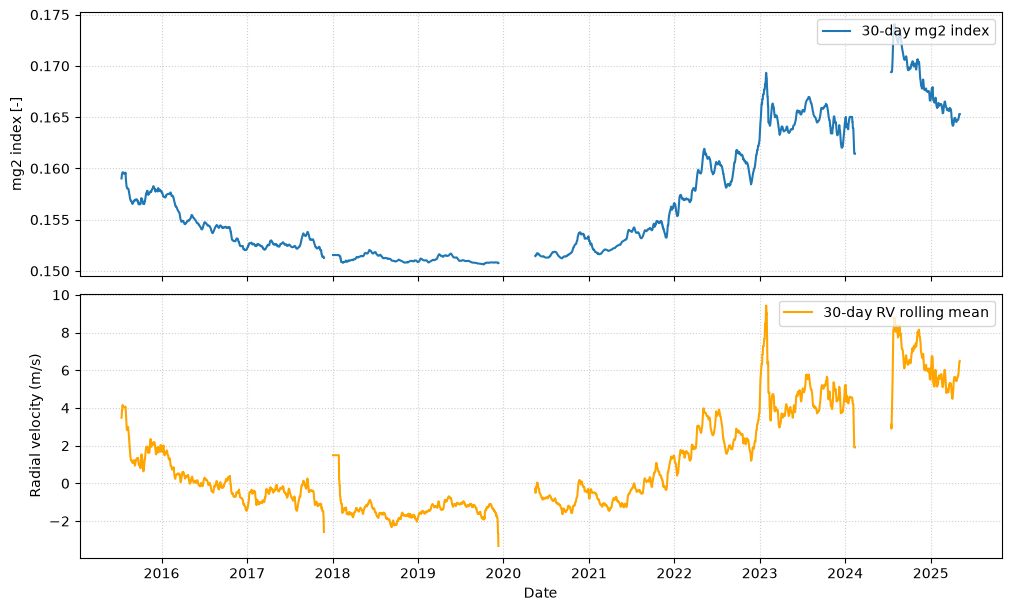

In [8]:
# Create a single plot
fig, (ax1,ax2) = plt.subplots(nrows=2, figsize=(10, 6), layout='constrained', sharex=True)

ax1.plot(smoothed_mg2_index.index, smoothed_mg2_index, label = '30-day mg2 index')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.set_ylabel('mg2 index [-]')
ax1.legend(loc='upper right')

ax2.plot(smoothed_solar_rvs.index, smoothed_solar_rvs, color='orange', label='30-day RV rolling mean')
ax2.set_ylabel('Radial velocity (m/s)')
ax2.set_xlabel('Date')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(loc='upper right')

plt.show()

The RV correction factor due to the magnetic cycle is given by:

\begin{equation}
  RV_{\text{Mg2}} = a \cdot Y_{\text{Mg2}} + b \tag{1}
\end{equation}

where $a$ is the linear slope and $b$ is the intercept obtained from the correlation with the Bremen composite activity index ($Y_{\text{Mg2}}$).

To correct the raw radial velocities, we subtract this correction factor from the measured velocities:

\begin{equation}
  RV_{\text{corrected}} = RV_{\text{raw}} - RV_{\text{Mg2}} = RV_{\text{raw}} - (a \cdot Y_{\text{Mg2}} + b)\tag{2}
\end{equation}

Note, RV and Mg2 index have been correlated before smoothing as this can bias the fit. 

In [9]:
slope, intercept, r, p, se = stats.linregress(mg2_index['mg2'].values, quality_df_rvs['rv'].values)
print(f"Magnetic activity correlated to solar RV by: {r:.4}")

Magnetic activity correlated to solar RV by: 0.9143


In [10]:
corrected_rvs = quality_df_rvs['rv'] - (slope*mg2_index['mg2'] + intercept) # w magnetic cycle correction
corrected_rvs.index = pd.to_datetime(quality_df_rvs['night'])

daily_corrected_rvs = corrected_rvs.groupby('night').mean() # daily-binned w magnetic cycle correction

smoothed_corrected_rvs = daily_corrected_rvs.rolling('30d', min_periods=1, center=True).mean() # w 30-day smooth

# calculate the RMS (root-mean-square) values
original_solar_smoothed_rms = np.sqrt(np.nanmean(smoothed_solar_rvs**2))
daily_binned_corrected_solar_rms = np.sqrt(np.nanmean(daily_corrected_rvs**2))
smoothed_solar_corrected_rms = np.sqrt(np.nanmean(smoothed_corrected_rvs**2))

/var/folders/ld/w2jbwdx97pgg_m7fmhgk5ks00000gp/T/ipykernel_86495/561768669.py:6: Pandas4Warning: 'd' is deprecated and will be removed in a future version, please use 'D' instead.
  smoothed_corrected_rvs = daily_corrected_rvs.rolling('30d', min_periods=1, center=True).mean() # w 30-day smooth


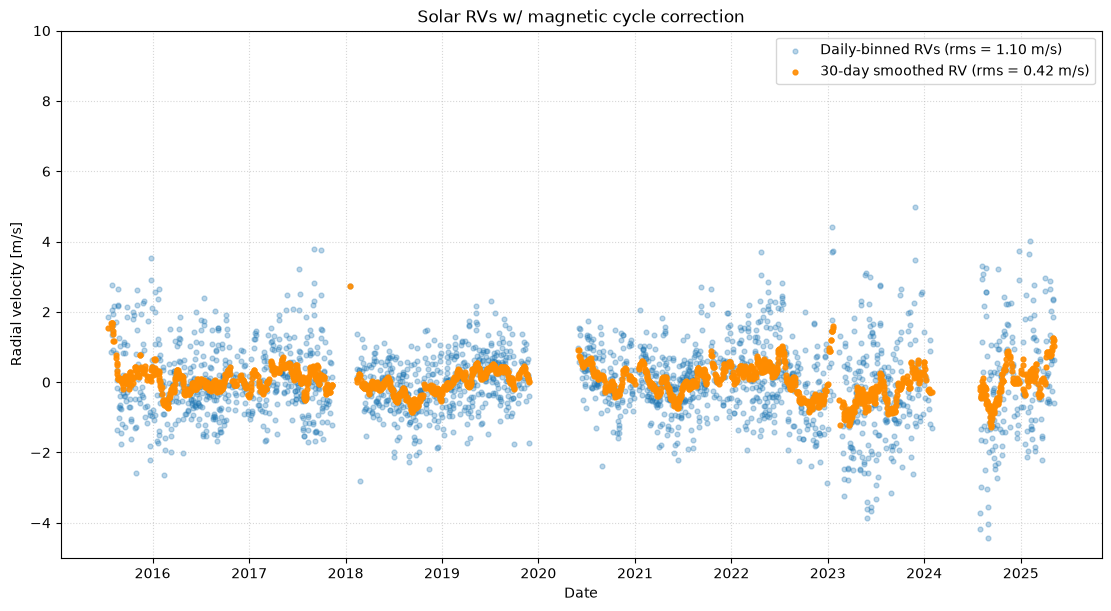

In [11]:
# Create a single plot comparing smoothed RV before and after correction.
fig, ax = plt.subplots(figsize=(11, 6), layout='constrained')

ax.scatter(daily_corrected_rvs.index, daily_corrected_rvs,alpha=0.3,
           s=12, label=f'Daily-binned RVs (rms = {daily_binned_corrected_solar_rms:.2f} m/s)', zorder=1)

ax.scatter(smoothed_corrected_rvs.index, smoothed_corrected_rvs, color='darkorange', alpha=0.9,
           label=f'30-day smoothed RV (rms = {smoothed_solar_corrected_rms:.2f} m/s)', s=12, zorder=2)

ax.grid(True, linestyle=':', alpha=0.5)
ax.set_ylabel('Radial velocity [m/s]')
ax.set_xlabel('Date')
ax.set_title('Solar RVs w/ magnetic cycle correction', fontsize=12)
ax.legend(loc='upper right')
ax.set_ylim([-5, 10])

plt.show()

## Lomb-Scargle periodogram
A Lomb-Scargle periodogram is calculated from the daily binned and 30-day smoothed RV time series. A Lomb-Scargle periodogram shows the normalised power as a function of period (power spectrum), however as with classical Fourier series analysis that assumes even sampling intervals, Lomb-Scargle drops that assumption and is based on a weighted least-squares fit of the form:

\begin{equation}
  y(t) = a \cos(\omega t) + b \sin(\omega t) + c \tag{3}
\end{equation}

with a fit calculated for each frequency independently.

In [12]:
def calc_pgram(nout, fmin, fmax, rv_signal):

    freqs_cycles_per_day = np.linspace(fmin, fmax, nout) # linear in frequency space from fmin to fmax with nout points.
    periods_days = 1.0 / freqs_cycles_per_day
    f = 2 * np.pi * freqs_cycles_per_day # scipy expects angular frequency in radians per day, hence the 2*pi factor.

    valid_daily_mask = ~np.isnan(rv_signal.values) #lomb-scargle requires valid data points, so we create a mask to filter out NaN values.
    x_daily = rv_signal.index[valid_daily_mask].to_julian_date()
    y_daily = rv_signal.values[valid_daily_mask]

    pgram_power = lombscargle(x_daily, y_daily, f, normalize=False, floating_mean=True) # power spectrum
    pgram_norm = lombscargle(x_daily, y_daily, f, normalize=True, floating_mean=True) # 0-1
    pgram_amp = lombscargle(x_daily, y_daily, f, normalize='amplitude', floating_mean=True) # complex; abs() -> m/s

    return periods_days, pgram_power, pgram_norm, pgram_amp

In [13]:
nout = 10002

fmin = 1.0 / 10000.0
fmax = 1.0 / 2.5 # avoid 1-day sampling peak

periods_days, daily_pgram_power, daily_pgram_norm, daily_pgram_amp = calc_pgram(nout, fmin, fmax, daily_corrected_rvs)
periods_days, smoothed_pgram_power, smoothed_pgram_norm, smoothed_pgram_amp = calc_pgram(nout, fmin, fmax, smoothed_corrected_rvs)

As was shown in [[Dumusque et al.](https://doi.org/10.1051/0004-6361/202557132)], the 30 day smoothing absorbs signals up to 150 days and both datasets give same signals above 150 days.

***Q: How do they calculate false-alarm probabilities in the paper?***

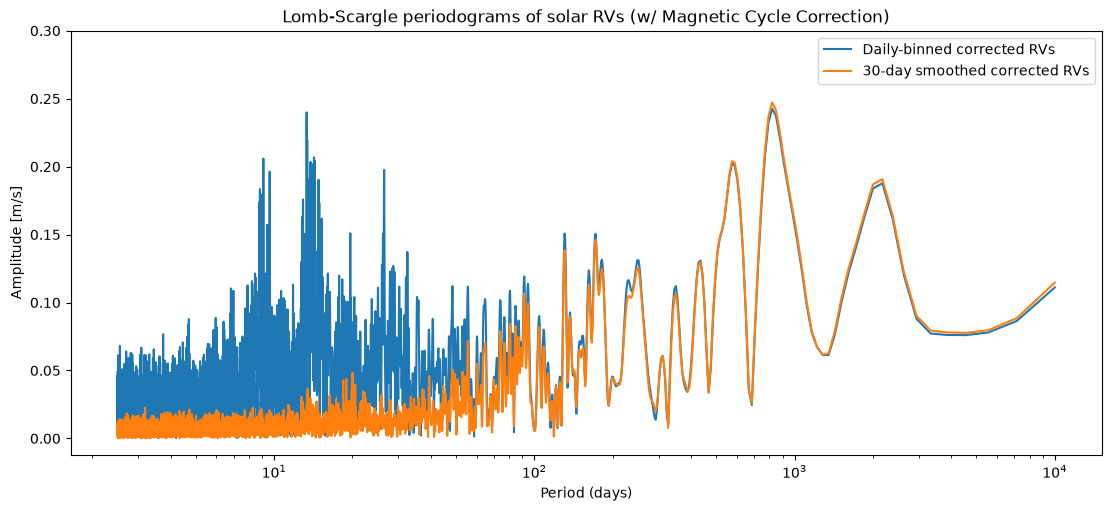

In [14]:
fig, ax = plt.subplots(figsize=(11, 5), layout='constrained')

# Plot both Normalized Power series on top of each other
ax.plot(periods_days, abs(daily_pgram_amp), color='#1f77b4', label='Daily-binned corrected RVs')
ax.plot(periods_days, abs(smoothed_pgram_amp), color='#ff7f0e', label='30-day smoothed corrected RVs')

ax.set_title('Lomb-Scargle periodograms of solar RVs (w/ Magnetic Cycle Correction)', fontsize=12)
ax.set_xlabel('Period (days)')
ax.set_ylabel('Amplitude [m/s]')
ax.set_xscale('log')
ax.set_ylim(ymax=0.3)
ax.legend(loc='upper right')

plt.show()

In [15]:
# Find the peak for the 30-day smoothed corrected RVs
smoothed_peak_idx = np.argmax(smoothed_pgram_norm)
smoothed_peak_period = periods_days[smoothed_peak_idx]
smoothed_peak_amp = abs(smoothed_pgram_amp)[smoothed_peak_idx]

print(f"Peak Period: {smoothed_peak_period:.0f} days")
print(f"Peak Amplitude: {smoothed_peak_amp:.2f} m/s")

Peak Period: 848 days
Peak Amplitude: 0.24 m/s


For periods above 150 days, the detection limit is set by the peak amplitude. Planet signal would need to stand out more than this!

## Combining stellar activity with modelled RVs

***Method below taken from Hara & Ford (2023) [[2]](https://doi.org/10.1146/annurev-statistics-033021-012225).***

The observed radial velocity $y(t)$ at any given time is modelled as the sum of the planetary Keplerian signals and an additional noise term, $\epsilon(t)$:

\begin{equation}
  y(t) = RV(t) + \epsilon(t) \tag{4}
\end{equation}

where the noise term at each observation time $t_i$ is treated as a Gaussian random variable assumed indepedent. An extra gaussian noise term, called jitter, is added that represents unmodelled planets, instrumental measurement errors and stellar variability:

\begin{equation}
  \epsilon(t_i) \sim \mathcal{N}(0, \sigma_{i}^2 + \sigma_{J}^2) \tag{5}
\end{equation}

where $\epsilon(t_i)$ follows a Gaussian distribution of variance $\sigma_{i}^2 + \sigma_{J}^2$.

The combined RV from the spectra can be expressed as:

\begin{equation}
  \widehat{RV(t_i)} = RV(t_i) + RV_{\text{contam}}(t_i) + \epsilon(t_i) \tag{6}
\end{equation}

and

\begin{equation}
  RV(t_i) = RV_{\text{planets}}(t_i) + RV_g(t_i), \quad i = 1, \dots, N \tag{7}
\end{equation}

with $RV_{\text{contam}}(t_i)$ as the RV caused by stellar variability and instrument systematics and $\epsilon(t_i)$ the photon noise.

RV variances induced by a star do not have a constant frequency, phase and amplitude, so cause the spectrum to also change with time and don't affect all lines identically.

## Injecting HARPS-N solar data

Using the HARPS-N solar data, we 'inject' this into our 10-year baseline of the combined solar-system planetary RV signal.

For timestamps where HARPS-N solar data contain NaN values, we also give the planetary signal a NaN value.

The HARPS-N solar data that we add to the planetary signal will be the solar data after the magnetic cycle correction and 30-day smoothing that mitigates stellar activity from the Sun.

In [16]:
planet_dates = pd.date_range(start='2015-07-16', periods=len(radial_velocity[2]), freq='D')

earth_series = pd.Series(radial_velocity[2], index=planet_dates)

# Reindex to match timestamps of HARPS-N smoothed_corrected_rvs
earth_rvs = earth_series.reindex(smoothed_corrected_rvs.index)

contaminated_smoothed_rv = earth_rvs + smoothed_corrected_rvs
contaminated_daily_rv = earth_rvs + daily_corrected_rvs

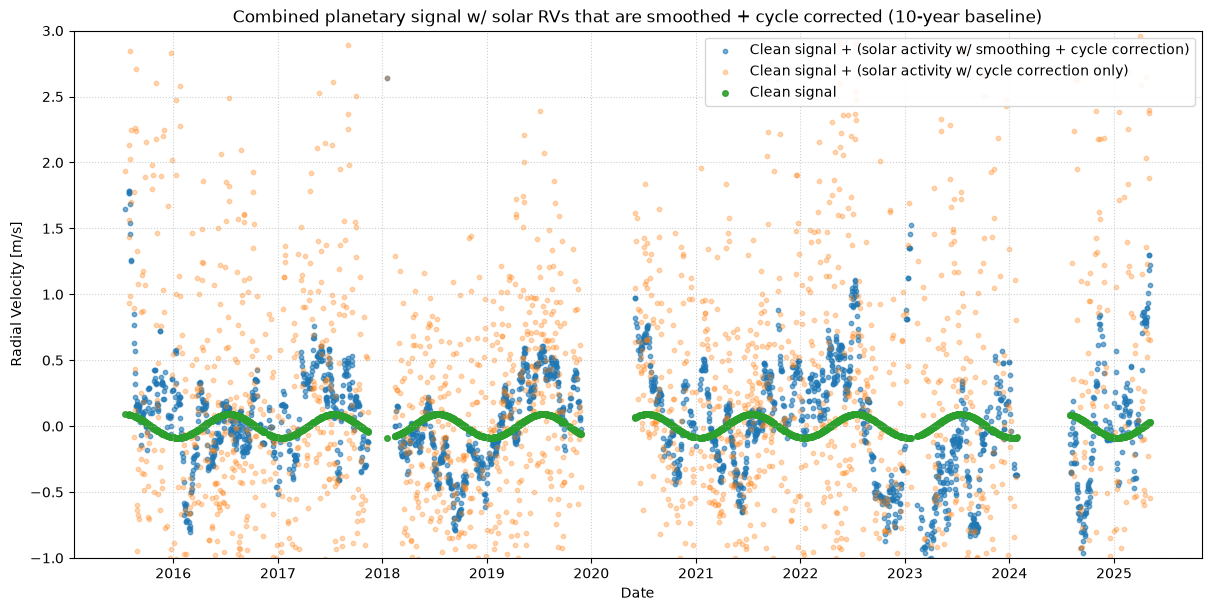

In [17]:
fig, ax = plt.subplots(figsize=(12, 6), layout='constrained')

# Scatter of planetary signal w/ solar activity w/ cycle correction and 30-day smoothing
ax.scatter(contaminated_smoothed_rv.index, contaminated_smoothed_rv, alpha=0.6,
           s=10, label=f'Clean signal + (solar activity w/ smoothing + cycle correction)')

# Scatter of planetary signal + solar activity w/ cycle correction only
ax.scatter(contaminated_daily_rv.index, contaminated_daily_rv, alpha=0.3,
           s=10, label=f'Clean signal + (solar activity w/ cycle correction only)')

# Scatter of the clean planetary signal
ax.scatter(earth_rvs.index, earth_rvs, alpha=0.9, s=16,
           label=f'Clean signal')

ax.grid(True, linestyle=':', alpha=0.6)
ax.set_ylabel('Radial Velocity [m/s]')
ax.set_xlabel('Date')
ax.set_title('Combined planetary signal w/ solar RVs that are smoothed + cycle corrected (10-year baseline)')

# Optimizing limits and legends
ax.set_ylim([-1, 3])
ax.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9, edgecolor='lightgray', fontsize=10)

plt.show()

## Calculating periodogram with stellar activity on top of planetary signal

In [18]:
periods_days, contaminated_smoothed_pgram_power, contaminated_smoothed_pgram_norm, contaminated_smoothed_pgram_amp = (
    calc_pgram(nout, fmin, fmax, contaminated_smoothed_rv)
)

_, contaminated_daily_pgram_power, contaminated_daily_pgram_norm, contaminated_daily_pgram_amp = (
    calc_pgram(nout, fmin, fmax, contaminated_daily_rv)
)

_, planetary_pgram_power, planetary_pgram_norm, planetary_pgram_amp = (
    calc_pgram(nout, fmin, fmax, earth_rvs)
)

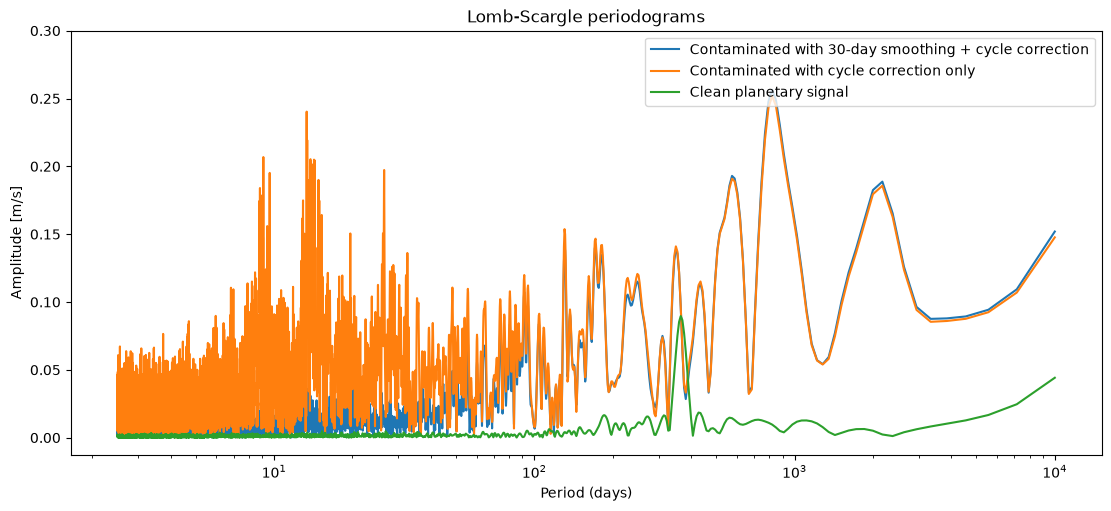

In [28]:
fig, ax = plt.subplots(figsize=(11, 5), layout='constrained')

# Plot both Normalized Power series on top of each other
ax.plot(periods_days, abs(contaminated_smoothed_pgram_amp),
        label='Contaminated with 30-day smoothing + cycle correction')
ax.plot(periods_days, abs(contaminated_daily_pgram_amp),
        label='Contaminated with cycle correction only')
ax.plot(periods_days, abs(planetary_pgram_amp),
        label='Clean planetary signal')

ax.set_title('Lomb-Scargle periodograms', fontsize=12)
ax.set_xlabel('Period (days)')
ax.set_ylabel('Amplitude [m/s]')
ax.set_xscale('log')
ax.set_ylim(ymax=0.3)
ax.legend(loc='upper right')

plt.show()

From the above graph, it can be seen that stellar activity causes low-frequency signals that can be mistaken for planets.

For the signal contaminated with the stellar acitivity that has been corrected for longer-term magnetic activity only, peaks emerge around the rotational period of the Sun.

Most periodograms scan for the orbital period one planet at a time; for multiple-planet systems, periodograms may be applied iteratively, identifying the most conspicous planet, then looking for a ($j$+1)th planet in the residuals of the best-fit model using $j$ planets.

# Fundamental photon noise limit to radial velocity measurements for HARPS3.
*Taken from [Bouchy, F., F. Pepe, and D. Queloz. “Fundamental Photon Noise Limit to Radial Velocity Measurements.” Astronomy & Astrophysics 374, no. 2 (2001): 733–39.](https://doi.org/10.1051/0004-6361:20010730).*

Considering that $N_{e^-}$ is the total number of photoelectrons counted over the whole spectral range, the uncertainty of the velocity change is given by:

$ \begin{equation}
V_{\mathrm{RMS}} = \frac{c}{Q\sqrt{N_{e^-}}}. 
\end{equation} \tag{8} $
With the quality factor Q and the total number of photoelectrons $N_{e^-}$, the fundamental noise limitation in velocity measurements can be calculated.

# References

[[1]](https://doi.org/10.1017/CBO9780511994852) - Perryman, Michael. The Exoplanet Handbook. 1st ed. Cambridge University Press, 2011.

[[2]](https://doi.org/10.1146/annurev-statistics-033021-012225) - Hara, Nathan C., and Eric B. Ford. “Statistical Methods for Exoplanet Detection with Radial Velocities.” Annual Review of Statistics and Its Application 10, no. 1 (2023): 623–49.

[[3]](https://doi.org/10.1051/0004-6361/202557132) - Dumusque, X., K. Al Moulla, M. Cretignier, et al. “A Decade of Solar High-Fidelity Spectroscopy and Precise Radial Velocities from HARPS-N.” Astronomy & Astrophysics 706 (February 2026): A231.
